In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.datasets import fetch_california_housing

In [14]:
housing = fetch_california_housing(as_frame= True)
X = housing.data
y = housing.target

print("Dataset Shape ", X.shape)
print("Target Shape: ", y.shape)
print("\nFeature Names:")
print(X.columns.tolist())


print("\nFirst Five Rows")
display(X.head())

print("\nMissing Values")
print(X.isnull().sum())

print("\nTarget Statistics")
print(y.describe())


Dataset Shape  (20640, 8)
Target Shape:  (20640,)

Feature Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

First Five Rows


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25



Missing Values
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

Target Statistics
count    20640.000000
mean         2.068558
std          1.153956
min          0.149990
25%          1.196000
50%          1.797000
75%          2.647250
max          5.000010
Name: MedHouseVal, dtype: float64


This helps us to observe the data:
X contains the input features, y contains the target values.
Each row of the dataset represents an observation, not just an individual feature.
The dataset contains 20640 observations, ditributed over 8 different features
None of the features has a missing value in the whole dataset.

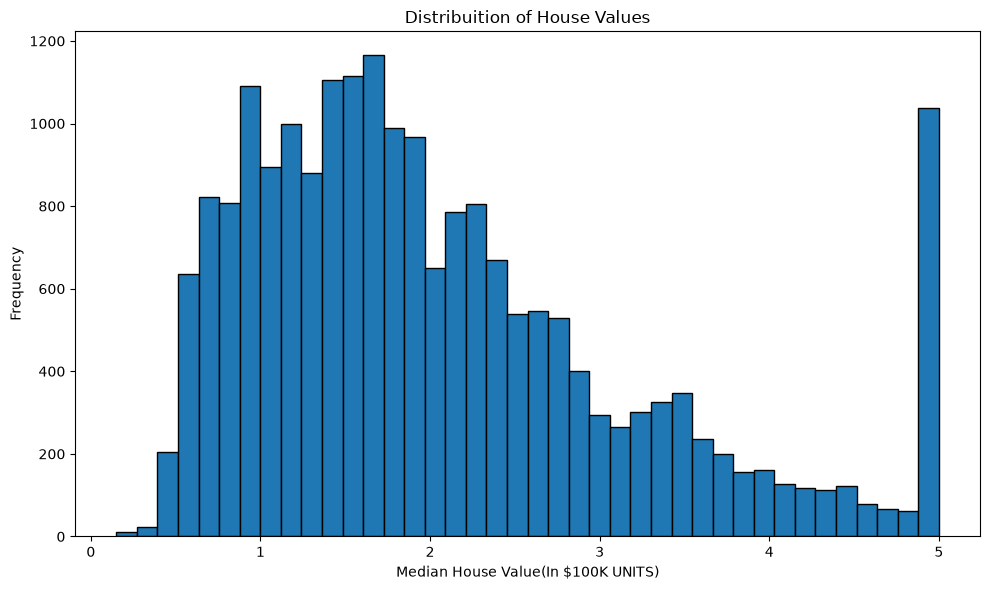

In [16]:
plt.figure(figsize=(10,6))
plt.hist(y, bins=40, edgecolor="black")
plt.xlabel("Median House Value(In $100K UNITS)")
plt.ylabel("Frequency")
plt.title("Distribuition of House Values")
plt.tight_layout()
plt.show()

This helps us to identify whether the target is symmetric or skewed or concentrated in specific price ranges.

In [17]:
from numpy import test
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20, random_state=42)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 16512
Testing samples: 4128


Here we reserved 80% of the data for model training and 20% for model testing.
Why data split? If we evaluate the model on the same data, we can only check how well the model remembers the training data rather than knowing how well the model will perform on unknown data.

In [18]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV

#Baseline: Ordinary Least Squares
linear_model = Pipeline([("scaler", StandardScaler()),("model", LinearRegression())])
linear_model.fit(X_train, y_train)

# Ridge: L2 regularization
ridge_pipeline = Pipeline([("scaler", StandardScaler()),("model", Ridge())])

# Lasso: L1 regularization
lasso_pipeline = Pipeline([("scaler", StandardScaler()), ("model", Lasso(max_iter=20000))])

#candidate regularozation strangths
alphavalues = np.logspace(-4, 3, 20)

#select alpha using 5-fold cross validation
ridge_search = GridSearchCV(ridge_pipeline, param_grid={"model__alpha": alphavalues}, scoring="neg_root_mean_squared_error", cv=5, n_jobs = -1)
lasso_search = GridSearchCV(lasso_pipeline, param_grid={"model__alpha": alphavalues}, scoring="neg_root_mean_squared_error", cv=5, n_jobs = -1)

ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)

models = {"Linear Regression": linear_model, "Ridge regression": ridge_search.best_estimator_, "Lasso Regression": lasso_search.best_estimator_}

print("Best Ridge Alpha:", ridge_search.best_params_["model__alpha"])
print("Best Lasso Alpha:",lasso_search.best_params_["model__alpha"])


Best Ridge Alpha: 0.0001
Best Lasso Alpha: 0.000545559478116852


In [21]:
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score)

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    results.append({"Model": name, "MAE": mean_absolute_error(y_test, y_pred), "RMSE":np.sqrt(mean_squared_error(y_test, y_pred)), "R2": r2_score(y_test, y_pred)})

results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4))


                      MAE    RMSE      R2
Model                                    
Linear Regression  0.5332  0.7456  0.5758
Ridge regression   0.5332  0.7456  0.5758
Lasso Regression   0.5332  0.7451  0.5764


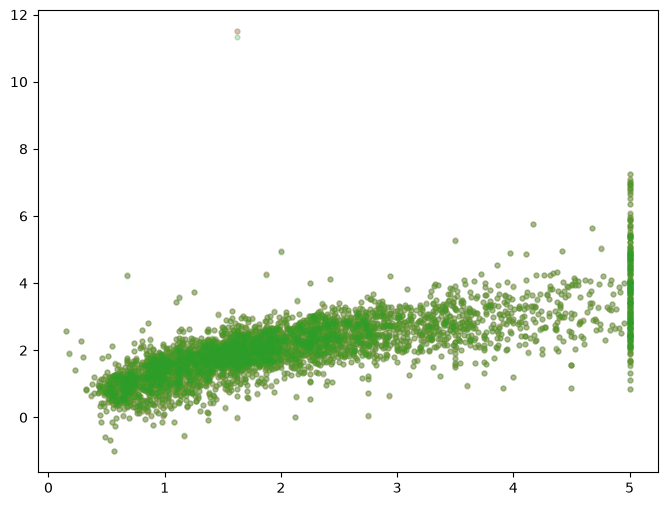

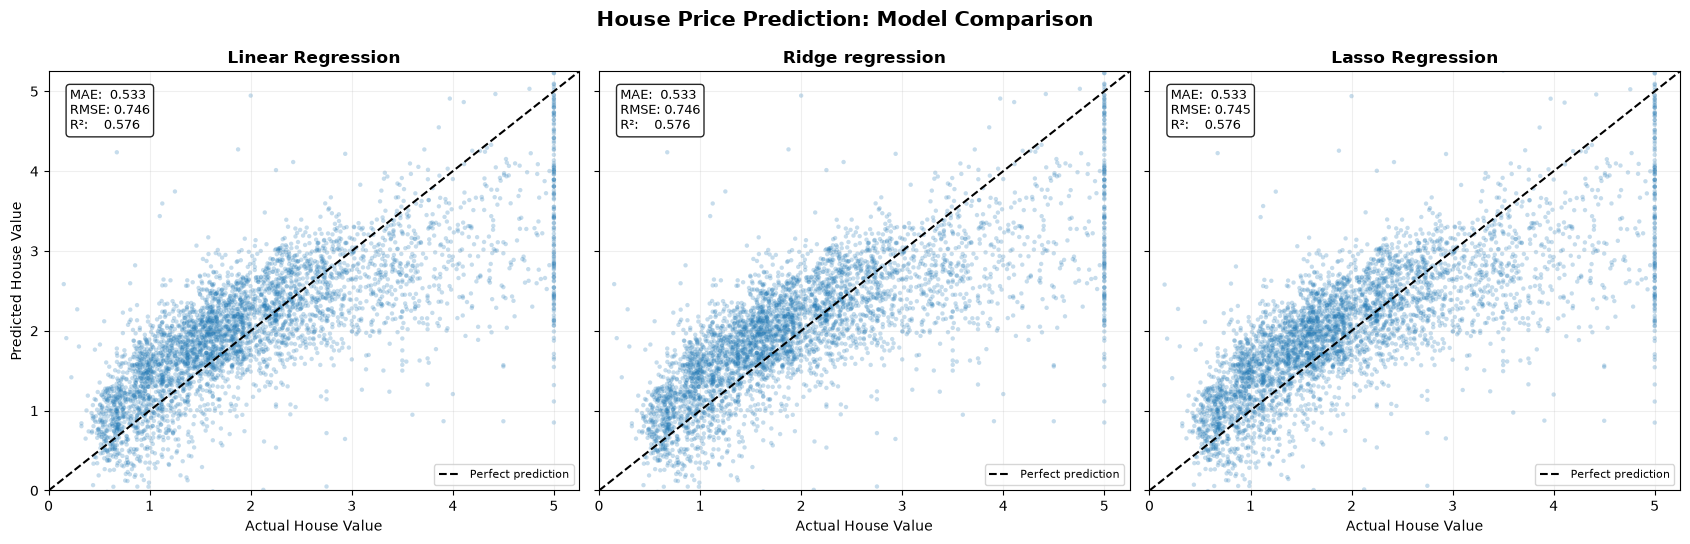

In [26]:
plt.figure(figsize = (8,6))

for name, y_pred in predictions.items():
    plt.scatter(y_test, y_pred, alpha=0.25, s=12, label=name)
lower = min(y_test.min(), *(p.min() for p in predictions.values()))
upper = max(y_test.max(), *(p.max() for p in predictions.values()))

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharex=True, sharey=True)


lower = min(0, float(y_test.min()))
upper = float(y_test.max()) * 1.05

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(
        y_test, y_pred,
        alpha=0.25,
        s=10,
        edgecolors="none",
        rasterized=True
    )

    ax.plot(
        [lower, upper], [lower, upper],
        "k--", linewidth=1.5, label="Perfect prediction"
    )

    
    metrics = results_df.loc[name]

    ax.text(
        0.04, 0.96,
        f"MAE:  {metrics['MAE']:.3f}\n"
        f"RMSE: {metrics['RMSE']:.3f}\n"
        f"R²:    {metrics['R2']:.3f}",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.85)
    )

    ax.set_xlim(lower, upper)
    ax.set_ylim(lower, upper)
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel("Actual House Value")
    ax.grid(alpha=0.2)
    ax.legend(loc="lower right", fontsize=8)

axes[0].set_ylabel("Predicted House Value")

fig.suptitle(
    "House Price Prediction: Model Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



In [31]:
# Check the selected hyperparameters
print("Best Ridge alpha:", ridge_search.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_search.best_params_["model__alpha"])

# Show metrics at higher precision
print("\nUnrounded evaluation metrics:")
print(results_df.to_string(float_format=lambda x: f"{x:.8f}"))

# Compare predictions against ordinary Linear Regression
baseline = predictions["Linear Regression"]

for name, pred in predictions.items():
    print(f"\n{name}")
    print("Max absolute prediction difference from Linear:",
          f"{np.max(np.abs(pred - baseline)):.10f}")
    print("Mean absolute prediction difference from Linear:",
          f"{np.mean(np.abs(pred - baseline)):.10f}")

# Compare fitted coefficients
for name in ["Ridge regression", "Lasso Regression"]:
    coef_diff = (
        models[name].named_steps["model"].coef_
        - models["Linear Regression"].named_steps["model"].coef_
    )
    print(f"\n{name} coefficient difference:")
    print(np.round(coef_diff, 8))

Best Ridge alpha: 0.0001
Best Lasso alpha: 0.000545559478116852

Unrounded evaluation metrics:
                         MAE       RMSE         R2
Model                                             
Linear Regression 0.53320013 0.74558138 0.57578771
Ridge regression  0.53320013 0.74558138 0.57578771
Lasso Regression  0.53316451 0.74505688 0.57638435

Linear Regression
Max absolute prediction difference from Linear: 0.0000000000
Mean absolute prediction difference from Linear: 0.0000000000

Ridge regression
Max absolute prediction difference from Linear: 0.0000007600
Mean absolute prediction difference from Linear: 0.0000000229

Lasso Regression
Max absolute prediction difference from Linear: 0.1612917412
Mean absolute prediction difference from Linear: 0.0031236691

Ridge regression coefficient difference:
[-1.e-08  1.e-08  2.e-08 -3.e-08  0.e+00 -0.e+00  8.e-08  8.e-08]

Lasso Regression coefficient difference:
[-0.00285409  0.00043759  0.00715642 -0.00719878  0.00068007  0.00051233
  0

In [33]:
lasso_model = models["Lasso Regression"].named_steps["model"]

coef_table = pd.DataFrame({
    "Feature": X.columns,
    "Linear": models["Linear Regression"]
        .named_steps["model"].coef_,
    "Ridge": models["Ridge regression"]
        .named_steps["model"].coef_,
    "Lasso": lasso_model.coef_
})

coef_table["Lasso_Zero"] = np.isclose(
    coef_table["Lasso"], 0.0
)

print(coef_table.to_string(index=False))
print("\nFeatures eliminated by Lasso:",
      coef_table.loc[coef_table["Lasso_Zero"], "Feature"].tolist())

   Feature    Linear     Ridge     Lasso  Lasso_Zero
    MedInc  0.854383  0.854383  0.851529       False
  HouseAge  0.122546  0.122546  0.122984       False
  AveRooms -0.294410 -0.294410 -0.287254       False
 AveBedrms  0.339259  0.339259  0.332061       False
Population -0.002308 -0.002308 -0.001628       False
  AveOccup -0.040829 -0.040829 -0.040317       False
  Latitude -0.896929 -0.896929 -0.890856       False
 Longitude -0.869842 -0.869842 -0.863420       False

Features eliminated by Lasso: []
